In [3]:
# =============================================================================
# COMPLETE CORRECTED CODE - TNG50-4 with SkewerJax
# =============================================================================

%load_ext autoreload
import logging
import numpy as np
import h5py
from scipy.spatial import cKDTree
from multiprocessing import Pool, cpu_count
import glob
import os
import sys

# Add parent directory to path
sys.path.append(os.path.abspath(".."))

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd
import skewerjax as sjx

import matplotlib.pyplot as plt
plt.rcdefaults()
plt.style.use('tableau-colorblind10')
%matplotlib widget

plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.titlesize': 12,
})

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# --- Physical Constants ---
PROTON_MASS = 1.6726e-24  # g
BOLTZMANN = 1.3807e-16    # erg/K
GAMMA = 5.0 / 3.0
XH = 0.76
h_hubble = 0.6774
z_sim = 3.01
scalefactor = 1.0 / (1.0 + z_sim)

# Unit conversion constants
Msun_kg = 1.9884e30
Mp_kg = 1.6726e-27
kpc_to_cm = 3.0857e21
X_H = 0.76

# --- SkewerJax Imports ---
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology
from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux
from skewerjax.optical_depth import line_profile
import skewerjax.optical_depth.optical_depth as od
from skewerjax.constants.physical_constants import phys
from skewerjax.optical_depth.voigt import Lorentzian

# --- Dirty-AstroPy Import ---
sys.path.insert(0, '/home/vroberto/Dirty_Astropy/Dirty-AstroPy/')
from galprops.galcalc import neutralFraction_SFcells, HI_H2_masses


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
# =============================================================================
# 1. DATA LOADING CLASS
# =============================================================================
class LoadSimulation:
    def __init__(self, base_path, n_workers=None, logger=None):
        self.base_path = base_path
        self.logger = logger or logging.getLogger(__name__)
        self.n_workers = n_workers or max(1, cpu_count() - 2)
        
    def _read_dataset(self, args):
        fname, path, unit = args
        with h5py.File(fname, "r") as f:
            return f[path][:] * unit

    def load_snapshot_data(self, particle_fields, pattern):
        files = np.sort(glob.glob(os.path.join(self.base_path, pattern)))
        data = {}
        
        for ptype, fields in particle_fields.items():
            for field, unit in fields.items():
                hdf5_path = f"{ptype}/{field}"
                tasks = [(f, hdf5_path, unit) for f in files]
                
                self.logger.info(f"Loading {hdf5_path}...")
                with Pool(self.n_workers) as pool:
                    chunks = pool.map(self._read_dataset, tasks)
                
                data[field] = np.concatenate(chunks, axis=0)
                
        return data

In [5]:
# =============================================================================
# 2. SPH SAMPLER FACTORY CLASS
# =============================================================================
class TNGSamplerFactory:
    def __init__(self, data, box_size, logger=None):
        self.data = data
        self.box_size = box_size
        self.logger = logger or logging.getLogger(__name__)
        self.coords = data["Coordinates"]
        
        if "SmoothingLength" in data:
            self.hsml = data["SmoothingLength"]
        else:
            self.logger.info("Estimating Smoothing Lengths...")
            vol = data["Masses"] / data["Density"] # Mpc³
            #self.hsml = (3 * vol / (4 * np.pi))**(1/3.0) #I did this before
            self.hsml = np.power(vol, 1.0/3.0) # That's how Fake_spectra.py does it
            self.hsml = np.maximum(self.hsml, 1e-6 * box_size)

        self.logger.info("Building cKDTree...")
        self.tree = cKDTree(self.coords, boxsize=box_size)
        self.logger.info("Tree built.")

    def _sph_kernel(self, r, h):
        q = r / h
        w = np.zeros_like(q)
        mask1 = (q <= 0.5)
        mask2 = (q > 0.5) & (q <= 1.0)
        w[mask1] = 8 * (1 - 6 * q[mask1]**2 + 6 * q[mask1]**3)
        w[mask2] = 16 * (1 - q[mask2])**3
        return w

    def make_field_sampler(self, field_name):
        if field_name not in self.data:
            raise ValueError(f"Field {field_name} not found in loaded data.")
            
        target_field = self.data[field_name]
        is_vector = target_field.ndim > 1
        
        def sampler(quadri_vectors):
            input_shape = quadri_vectors.shape[:-1]
            points_flat = quadri_vectors.reshape(-1, 4)
            coords_query = points_flat[:, 1:4]
            coords_query = np.mod(coords_query, self.box_size)

            search_radius = np.percentile(self.hsml, 99)
            neighbor_indices = self.tree.query_ball_point(coords_query, r=search_radius)

            n_points = coords_query.shape[0]
            if is_vector:
                output_flat = np.zeros((n_points, target_field.shape[1]))
            else:
                output_flat = np.zeros(n_points)

            for i, idxs in enumerate(neighbor_indices):
                if not idxs: continue
                
                idxs = np.array(idxs)
                local_pos = self.coords[idxs]
                local_hsml = self.hsml[idxs]
                
                d_vec = np.abs(local_pos - coords_query[i])
                d_vec = np.where(d_vec > 0.5 * self.box_size, self.box_size - d_vec, d_vec)
                dist = np.sqrt(np.sum(d_vec**2, axis=1))
                
                mask = dist < local_hsml
                if not np.any(mask): continue
                
                valid_idxs = idxs[mask]
                valid_dist = dist[mask]
                valid_h = local_hsml[mask]
                
                weights = self._sph_kernel(valid_dist, valid_h)
                sum_weights = np.sum(weights)
                
                if sum_weights > 0:
                    val = target_field[valid_idxs]
                    if is_vector:
                        weighted_val = np.sum(val * weights[:, None], axis=0)
                    else:
                        weighted_val = np.sum(val * weights)
                    output_flat[i] = weighted_val / sum_weights

            return output_flat.reshape(input_shape + ((-1,) if is_vector else ()))
            
        return sampler

    def  make_temperature_sampler(self):
        u_sampler = self.make_field_sampler("InternalEnergy")
        xe_sampler = self.make_field_sampler("ElectronAbundance")
        
        def sampler(quadri_vectors):
            u_vals = u_sampler(quadri_vectors)
            xe_vals = xe_sampler(quadri_vectors)
            
            mu = (4.0 / (1.0 + 3.0 * XH + 4.0 * XH * xe_vals))* PROTON_MASS
            u_cgs = u_vals * 1e10
            T = (GAMMA - 1) * (u_cgs / BOLTZMANN) * (mu)
            return T # K
            
        return sampler

In [6]:
# =============================================================================
# 3. LOAD TNG DATA
# =============================================================================
print("="*60)
print("LOADING TNG50-4 DATA")
print("="*60)

particle_fields = {
    "PartType0": {
        "Masses": 1e10 / h_hubble, # Msun
        "Coordinates": 1/(h_hubble*1e3), # Mpc
        "Density": 10**19 * h_hubble**2, # Msun/Mpc³
        "InternalEnergy": 1, # (km/s)²
        "ElectronAbundance": 1, # No units
        "Velocities": 1*np.sqrt(scalefactor), # km/s
        "NeutralHydrogenAbundance": 1, # No units
        "StarFormationRate": 1, # Msun/yr
    }
}

loader = LoadSimulation("/home/STORAGE/TNG50-4")
data_tng = loader.load_snapshot_data(particle_fields, "snapdir_025/snap_025.*.hdf5")

L_box_kpc = 35000.0 / h_hubble  # kpc
L_box_Mpc = L_box_kpc * 1e-3     # Mpc

print(f"\nBox size: {L_box_kpc:.1f} kpc = {L_box_Mpc:.4f} Mpc")

2026-02-04 10:47:57,398 - INFO - Loading PartType0/Masses...


LOADING TNG50-4 DATA


/home/vroberto/miniconda3/envs/skewerjax_fakespectra/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
/home/vroberto/miniconda3/envs/skewerjax_fakespectra/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2026-02-04 10:47:57,652 - INFO - Loading PartType0/Coordinates...
2026-02-04 10:47:58,527 - INFO - Loading PartType0/Density...
2026-02-04 10:47:58,755 - INFO - Loading PartType0/InternalEnergy...
2026-02-04 10:47:58,993 - INFO - Loading PartType0/ElectronAbundance...
2026-02-04 10:47:59,239 - INFO - Loading PartType0/Velocities...
2026-02-04 10:47:59,628 - INFO - Loading PartType0/NeutralHydrogenAbundance...
2026-02-04 10:47:59,945 - I


Box size: 51668.1 kpc = 51.6681 Mpc


In [7]:
# =============================================================================
# 4. CREATE SAMPLER FACTORY (coordinates in Mpc)
# =============================================================================
factory = TNGSamplerFactory(data_tng, box_size=L_box_Mpc)

# Base samplers (expect Mpc coordinates)
raw_density_sampler = factory.make_field_sampler("Density") # returns density in Msun/Mpc³
raw_nHI_frac_sampler = factory.make_field_sampler("NeutralHydrogenAbundance")
raw_SFR_sampler = factory.make_field_sampler("StarFormationRate")
raw_u_sampler = factory.make_field_sampler("InternalEnergy")
raw_velocity_sampler = factory.make_field_sampler("Velocities")
raw_temperature_sampler = factory.make_temperature_sampler()

2026-02-04 10:48:00,263 - INFO - Estimating Smoothing Lengths...
2026-02-04 10:48:00,376 - INFO - Building cKDTree...
2026-02-04 10:48:06,061 - INFO - Tree built.


In [8]:
# =============================================================================
# 4.5 RAHMATI PHYSICS HELPER (Ported from fake_spectra/gas_properties.py)
# =============================================================================
from scipy.interpolate import interp1d

class RahmatiCorrector:
    """
    Implements the self-shielding correction and Star Formation threshold 
    exactly as found in fake_spectra/gas_properties.py
    """
    def __init__(self, redshift, hubble=0.6774, fbar=0.17):
        self.redshift = redshift
        self.gamma_UVB = 1e-12 
        self.f_bar = fbar
        self.gamma = 5./3
        self.boltzmann = 1.38064852e-16
        self.protonmass = 1.6726219e-24

        # Tables from fake_spectra/gas_properties.py
        zz = [0, 1, 2, 3, 4, 5, 6]
        gamma_UVB_vals = [3.99e-14, 3.03e-13, 6e-13, 5.53e-13, 4.31e-13, 3.52e-13, 2.678e-13]
        gray_opac_vals = [2.59e-18, 2.37e-18, 2.27e-18, 2.15e-18, 2.02e-18, 1.94e-18, 1.82e-18]
        
        self.gamma_inter = interp1d(zz, gamma_UVB_vals, fill_value="extrapolate")
        self.gray_inter = interp1d(zz, gray_opac_vals, fill_value="extrapolate")
        
        self.gamma_UVB = self.gamma_inter(redshift)
        self.gray_opac = self.gray_inter(redshift)
        
        # Standard TNG SF Threshold ~0.13 atoms/cm^3
        # Calculating it dynamically is prone to unit errors, using canonical value.
        self.PhysDensThresh = 0.128 

    def get_neutral_fraction(self, nH, temp):
        # nH [atoms/cm^3], temp [K]
        T4 = temp / 1e4
        G12 = self.gamma_UVB / 1e-12
        nSSh = 6.73e-3 * (self.gray_opac / 2.49e-18)**(-2./3) * T4**0.17 * G12**(2./3) * (self.f_bar / 0.17)**(-1./3)
        
        photo_rate = self.gamma_UVB * (0.98 * (1 + (nH/nSSh)**1.64)**(-2.28) + 0.02 * (1 + nH/nSSh)**(-0.84))
        
        lamb = 315614.0 / temp
        alpha_A = 1.269e-13 * lamb**1.503 / (1 + (lamb/0.522)**0.47)**1.923
        LambdaT = 1.17e-10 * temp**0.5 * np.exp(-157809.0 / temp) / (1 + np.sqrt(temp/1e5))
        
        A = alpha_A + LambdaT
        B = 2*alpha_A + photo_rate/nH + LambdaT
        return (B - np.sqrt(B**2 - 4*A*alpha_A)) / (2*A)

# Initialize global corrector
rahmati = RahmatiCorrector(z_sim, h_hubble)

In [9]:
# =============================================================================
# 5. CORRECTED HI SAMPLER (Rahmati Physics + Unit Fix)
# =============================================================================
def nHI_physical_sampler_safe(quadri_vectors):
    """
    Calculates n_HI applying Rahmati correction for Star Forming gas.
    
    Logic:
    1. Sampling: Gets Comoving Density in Msun/Mpc^3.
    2. Physics: Converts to Physical CGS (g/cm^3) to apply Rahmati (Self-Shielding).
    3. Output: Converts back to Comoving Number Density (atoms/cm^3) for the integrator.

    Input: quadri_vectors [Mpc] (Comoving)
    Output: n_HI [atoms/cm^3] (Comoving)
    """
    # 1. Prepare Coordinates
    # Input is already in Mpc (Comoving), matching the Tree and BoxSize.
    qv = np.asarray(quadri_vectors)
    
    # 2. Get Comoving Density from TNG (Msun / cMpc^3)
    rho_com_Msun_Mpc3 = raw_density_sampler(qv) 
    
    # 3. Convert to Physical Density in CGS (g / cm^3)
    # Factor A: Unit Conversion (Msun/Mpc^3 -> g/cm^3)
    # Msun = 1.98847e33 g
    # Mpc  = 3.085678e24 cm
    conv_units = Msun_kg * 1000 / (kpc_to_cm * 1000)**3 # approx 6.76e-41
    
    # Factor B: Cosmological Conversion (Comoving -> Physical)
    # rho_phys = rho_com * (1+z)^3  <=>  rho_phys = rho_com / a^3
    rho_phys_cgs = rho_com_Msun_Mpc3 * conv_units * (scalefactor**-3)
    
    # 4. Calculate Total Hydrogen Number Density (Physical)
    # n_H = rho * X_H / m_p
    # Check if XH sampler exists (for variable metallicity), else default to 0.76
    # Note: You didn't initialize raw_XH_sampler in your prompt code, so defaulting to 0.76
    XH = 0.76
        
    nH_total_phys = (rho_phys_cgs * XH) / PROTON_MASS # [atoms/cm^3] (Physical)
    
    # 5. Get 'Raw' Neutral Fraction from Simulation
    f_neutral = raw_nHI_frac_sampler(qv)
    
    # 6. Apply Rahmati Correction (Self-Shielding)
    # This must be done using PHYSICAL density
    thresh = rahmati.PhysDensThresh # Threshold in atoms/cm^3 (Physical)
    
    # Identify dense gas (Star Forming regions)
    is_dense = nH_total_phys > thresh
    
    final_f_neutral = f_neutral.copy()
    
    if np.any(is_dense):
        # Recalculate neutral fraction assuming T=10^4 K for SF gas (Standard approach)
        # We pass nH_total_phys (CGS) to the Rahmati calculator
        f_rah = rahmati.get_neutral_fraction(nH_total_phys[is_dense], 1.0e4)
        final_f_neutral[is_dense] = f_rah
        
    # 7. Calculate n_HI (Physical)
    n_HI_phys = nH_total_phys * final_f_neutral # [atoms/cm^3] (Physical)
    
    # 8. Convert back to Comoving Number Density
    # The integrator (optical_depth.py) expects Comoving Density because it uses dtau = n_com * sigma * a^-2 * dx
    # n_com = n_phys * a^3
    n_HI_comoving = n_HI_phys * (scalefactor**3)
    
    # Return with floor to avoid log errors later
    return np.maximum(n_HI_comoving, 1e-20)


def get_temperature_mpc_safe(quadri_vectors):
    """Temperature [K] with Mpc->kpc conversion and zero protection."""
    qv = np.asarray(quadri_vectors).copy()
    
    # REMOVED: qv[..., 1:4] *= 1e3 conversion. 
    # Your Factory expects Mpc if initialized with L_box_Mpc.
    # Assuming raw_temperature_sampler handles the Mpc input correctly (from Factory).
    T = raw_temperature_sampler(qv)
    
    # Replace zeros with typical IGM temperature
    T = np.where(T == 0, 1e-1, T)
    T = np.where(np.isnan(T) | np.isinf(T), 1e4, T)
    T = np.clip(T, 1e0, 1e12)
    
    return T


def get_velocity_mpc_safe(quadri_vectors):
    """Velocity [km/s] with Mpc->kpc conversion and NaN protection."""
    qv = np.asarray(quadri_vectors).copy()
    
    # REMOVED: qv[..., 1:4] *= 1e3 conversion.
    v = raw_velocity_sampler(qv)
    v = np.where(np.isnan(v) | np.isinf(v), 0.0, v)
    
    return v

In [10]:
# =============================================================================
# 6. CREATE FIELDS FOR SKEWERJAX
# =============================================================================
fields = Fields({
    "HI": {
        "temperature": ScalarField(get_temperature_mpc_safe), # Temperature [K]      
        "velocity": VectorField(get_velocity_mpc_safe), # Velocity [km/s]
        "number_density": ScalarField(nHI_physical_sampler_safe), # n_HI [cm^-3] 
        "turbulence": ScalarField(lambda x: jnp.zeros(jnp.asarray(x).shape[:-1])), # Turbulence [km/s]
        "collisional": ScalarField(lambda x: jnp.zeros(jnp.asarray(x).shape[:-1])), # Collisional [km/s]
    }
})

print("\nFields created with safe samplers")


Fields created with safe samplers


In [11]:
# =============================================================================
# 7. CREATE CUSTOM SKEWER POINTS
# =============================================================================
N_sk = 1
N_ppsk = 1024

# Create points along x-axis, at y=z=L/2 (center of box)
x_coords = jnp.linspace(0, L_box_Mpc, N_ppsk)  # include edges
y_coords = jnp.full(N_ppsk, L_box_Mpc / 2)
z_coords = jnp.full(N_ppsk, L_box_Mpc / 2)

# Shape: (N_sk, N_ppsk, 3)
_points_custom = jnp.stack([x_coords, y_coords, z_coords], axis=-1)[None, :, :]

print(f"\nSkewer configuration:")
print(f"  N_skewers: {N_sk}")
print(f"  N_points_per_skewer: {N_ppsk}")
print(f"  x: [{float(_points_custom[0, 0, 0]):.2f} ... {float(_points_custom[0, -1, 0]):.2f}] Mpc")
print(f"  y: {float(_points_custom[0, 0, 1]):.2f} Mpc (constant, box center)")
print(f"  z: {float(_points_custom[0, 0, 2]):.2f} Mpc (constant, box center)")


Skewer configuration:
  N_skewers: 1
  N_points_per_skewer: 1024
  x: [0.00 ... 51.67] Mpc
  y: 25.83 Mpc (constant, box center)
  z: 25.83 Mpc (constant, box center)


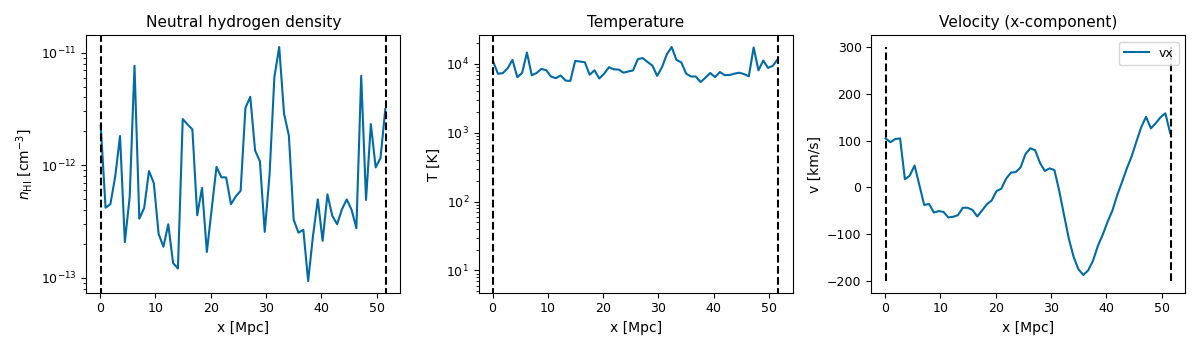

In [12]:
# =============================================================================
# DEBUG: Visualize fields along the skewer
# =============================================================================

N_debug = 60
x_debug = np.linspace(0.1, L_box_Mpc - 0.1, N_debug)

qv_debug = np.zeros((N_debug, 4))
qv_debug[:, 0] = scalefactor
qv_debug[:, 1] = x_debug
qv_debug[:, 2] = L_box_Mpc / 2
qv_debug[:, 3] = L_box_Mpc / 2

nHI_debug = nHI_physical_sampler_safe(qv_debug)
density_debug = raw_density_sampler(qv_debug)
T_debug = get_temperature_mpc_safe(qv_debug)
v_debug = get_velocity_mpc_safe(qv_debug)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

ax = axes[0]
ax.semilogy(x_debug, nHI_debug)
ax.set_xlabel('x [Mpc]')
ax.set_ylabel(r'$n_{\rm HI}$ [cm$^{-3}$]')
ax.vlines(x=0.1, ymin=0, ymax=1e-5, color='k', ls='--', lw=1.5)
ax.vlines(x=L_box_Mpc, ymin=0, ymax=1e-5, color='k', ls='--', lw=1.5)
ax.set_title('Neutral hydrogen density')

ax = axes[1]
ax.semilogy(x_debug, T_debug)
ax.set_xlabel('x [Mpc]')
ax.set_ylabel('T [K]')
ax.vlines(x=0.1, ymin=0, ymax=1e7, color='k', ls='--', lw=1.5)
ax.vlines(x=L_box_Mpc, ymin=0, ymax=1e7, color='k', ls='--', lw=1.5)
ax.set_title('Temperature')

ax = axes[2]
ax.plot(x_debug, v_debug[:, 0], label='vx')
ax.set_xlabel('x [Mpc]')
ax.set_ylabel('v [km/s]')
ax.set_title('Velocity (x-component)')
ax.vlines(x=0.1, ymin=-200, ymax=300, color='k', ls='--', lw=1.5)
ax.vlines(x=L_box_Mpc, ymin=-200, ymax=300, color='k', ls='--', lw=1.5)

ax.legend()

plt.tight_layout()
plt.show()


Expected n_HI range for IGM at z~3: 1e-10 to 1e-5 cm⁻³
Your n_HI range: 9.34e-14 to 1.12e-11 cm⁻³


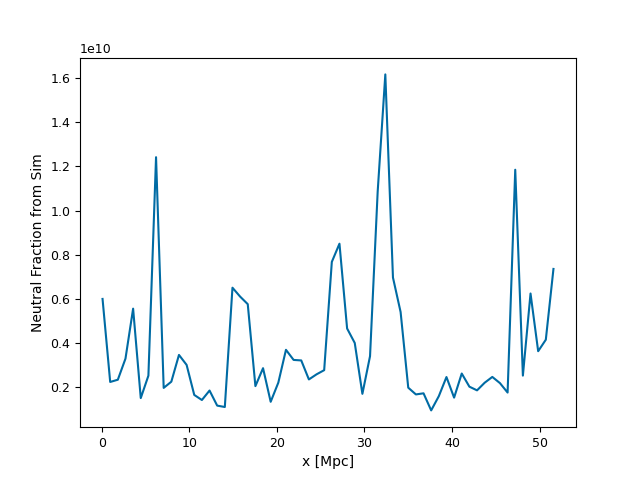

In [13]:
print(f"\nExpected n_HI range for IGM at z~3: 1e-10 to 1e-5 cm⁻³")
print(f"Your n_HI range: {nHI_debug.min():.2e} to {nHI_debug.max():.2e} cm⁻³")
rho_comoving = raw_density_sampler(qv_debug) # Msun/kpc³ comoving
frac_from_sim = raw_nHI_frac_sampler(qv_debug)
rho_comoving[0], frac_from_sim[0]

plt.close("all")
plt.plot(x_debug, rho_comoving)
plt.xlabel('x [Mpc]')
plt.ylabel('Neutral Fraction from Sim')
plt.show()

In [14]:
# =============================================================================
# 9. SETUP COSMOLOGY AND SKEWER BUNDLE
# =============================================================================
cosmology = Cosmology(
    H0=phys.H0,
    Omega_r_0=0.0,
    Omega_m_0=0.3089,
    Omega_k_0=0.0,
    Omega_lambda_0=0.6911,
)

skewer_bundle = SkewerBundle(
    spatial_points=_points_custom,
    a0=0.25,
    x0=0.0,
    ICs_defined_at_index=0,
    ICs_at_emission_or_absorption="absorption",
    los_directions=None,
    cosmologies=cosmology
)

2026-02-04 10:48:07,749 - INFO - Initializing SkewerBundle with 1 skewers, 1024 points per skewer
2026-02-04 10:48:07,768 - INFO - Broadcasting scalar ICs_defined_at_index=0 to all 1 skewers
2026-02-04 10:48:07,776 - INFO - All skewers set to absorption mode


2026-02-04 10:48:07,802 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-02-04 10:48:07,915 - INFO - Computing comoving distances along skewer direction
2026-02-04 10:48:07,998 - INFO - Computing scale factors from cosmology
2026-02-04 10:48:09,398 - INFO - Storing quadri-vectors
2026-02-04 10:48:09,427 - INFO - SkewerBundle initialization complete


In [15]:
# =============================================================================
# 10. COMPUTE OPTICAL DEPTH
# =============================================================================
print("\n" + "="*60)
print("COMPUTING OPTICAL DEPTH")
print("="*60)

wavelengths = jnp.linspace(1215.6720277988175, 1231.732194431588, 3961)
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA"])

optical_depth = od.compute_optical_depth(
    skewer_bundle,
    wavelengths,
    line_bundle,
    fields, 
    box_velocity_kms=3961.55
)

F_over_F0 = jnp.exp(-optical_depth)

2026-02-04 10:48:09,486 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, mode=pmap, Voigt impl=ExoJAX
2026-02-04 10:48:09,487 - INFO - [OPTICAL_DEPTH] Extracting 1 skewers with 1024 points each
2026-02-04 10:48:09,511 - INFO - [OPTICAL_DEPTH] Computing line profiles for 1 lines across 1 species using pmap



COMPUTING OPTICAL DEPTH


2026-02-04 10:48:10,347 - INFO - Detected 1 device(s) for pmap.
2026-02-04 10:48:10,506 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (1, 1, 1024, 3961)
2026-02-04 10:48:10,506 - INFO - [OPTICAL_DEPTH] Tiling fields for 1 species to line-level
2026-02-04 10:48:10,828 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (1, 1, 1024)
2026-02-04 10:48:10,828 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-02-04 10:48:10,899 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (1, 1, 1024, 3961)
2026-02-04 10:48:10,900 - INFO - [OPTICAL_DEPTH] Reorienting 1 skewers based on photon path direction mask
2026-02-04 10:48:10,986 - INFO - [OPTICAL_DEPTH] Arrays reoriented: quadri_vectors (1, 1024, 4), dtau_dx_m (1, 1, 1024, 3961)
2026-02-04 10:48:10,987 - INFO - [OPTICAL_DEPTH] Performing trapz integration along 1024 spatial points
2026-02-04 10:48:11,015 - INFO - [OPTICAL_DEPTH] Computation complete. Result shape: (1, 1, 3961)


In [16]:
optical_depth

Array([[[1.071815 , 1.0664322, 1.063359 , ..., 1.1554834, 1.1258475,
         1.1039479]]], dtype=float32)

In [17]:
print(f"\nResults:")
print(f"  Optical depth shape: {optical_depth.shape}")
print(f"  Has NaN: {bool(jnp.any(jnp.isnan(optical_depth)))}")
print(f"  τ range: [{float(jnp.nanmin(optical_depth)):.2e}, {float(jnp.nanmax(optical_depth)):.2e}]")
print(f"  Flux range: [{float(F_over_F0.min()):.4f}, {float(F_over_F0.max()):.4f}]")


Results:
  Optical depth shape: (1, 1, 3961)
  Has NaN: False
  τ range: [3.09e-02, 3.01e+01]
  Flux range: [0.0000, 0.9696]


In [18]:
optical_depth.shape, F_over_F0.shape

((1, 1, 3961), (1, 1, 3961))

In [19]:
skewer_bundle.quadri_vectors[0,0,-1]

Array([ 0.24671142, 51.668144  , 25.834072  , 25.834072  ], dtype=float32)

In [20]:
L_box_Mpc

51.668142899320934

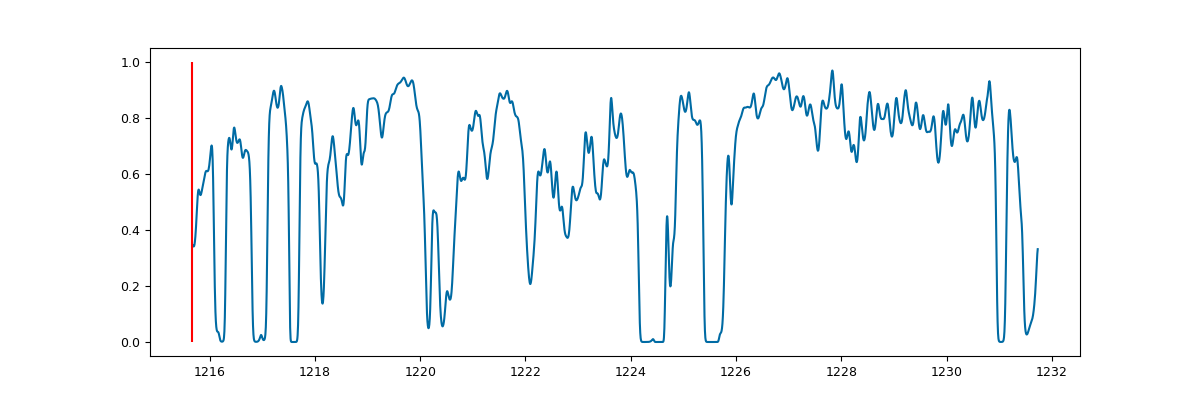

In [42]:
plt.close('all')
plt.figure(figsize=(12, 4))
plt.plot(wavelengths, F_over_F0[0,0,:])
# plt.xlim(1215, 1232)
plt.vlines(1215.67, 0, 1, color='red')
plt.show()

# =================================================================================
### Comparisson with Homogeneous box
# =================================================================================

In [22]:
# =============================================================================
# 1. SIMPLE BOX GENERATOR (UNIFORM ONLY)
# =============================================================================

def create_uniform_box(N_particles, L_box, seed=42):
    """Create a uniform box with constant fields."""
    rng = np.random.default_rng(seed)
    
    # Positions
    coords = rng.uniform(0, L_box, size=(N_particles, 3))
    
    # Constant fields
    data = {
        'Coordinates': coords,
        'Density': np.full(N_particles, 1e12),              # Msun/cMpc³
        'NeutralHydrogenAbundance': np.full(N_particles, 1e-5),
        'Velocities': np.zeros((N_particles, 3)),           # km/s
    }
    
    # Smoothing length
    n_density = N_particles / L_box**3
    h = (3 * 32 / (4 * np.pi * n_density))**(1/3)
    data['SmoothingLength'] = np.full(N_particles, h)
    
    print(f"Created box: N={N_particles}, L={L_box:.2f} cMpc/h, h={h:.4f} cMpc/h")
    return data

In [23]:
# =============================================================================
# 3. CREATE BOX AND SAMPLERS
# =============================================================================

# Box parameters
N_particles = 100000

# Create box
data_uniform = create_uniform_box(N_particles, L_box_Mpc)

# Create SPH sampler
sph = TNGSamplerFactory(data_uniform, L_box_Mpc)

2026-02-04 10:48:11,816 - INFO - Building cKDTree...
2026-02-04 10:48:11,832 - INFO - Tree built.


Created box: N=100000, L=51.67 cMpc/h, h=2.1924 cMpc/h


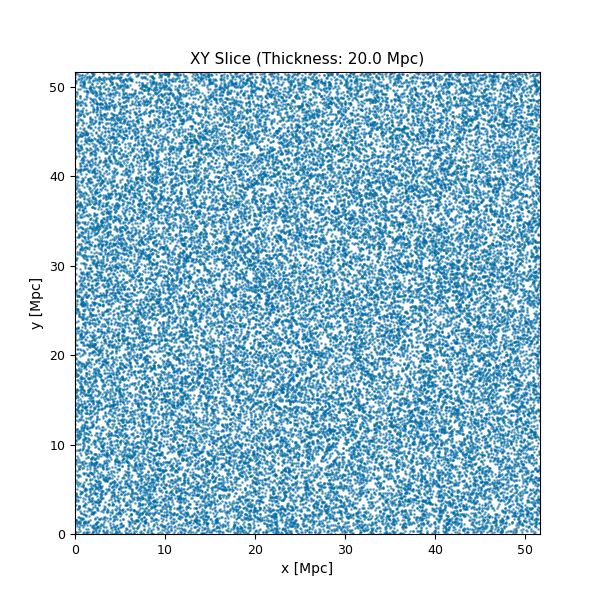

In [24]:
# Plotting a slice of the positions of the particles in the uniform box: 
z_center = L_box_Mpc/2
thickness = 20.0 # Mpc
coords_x = sph.coords[:,0]
coords_y = sph.coords[:,1]
coords_z = sph.coords[:,2]

# 3. Filter particles that are inside the Z slice
mask = (coords_z > (z_center - thickness/2)) & (coords_z < (z_center + thickness/2))

plt.close('all')
plt.figure(figsize=(6,6))
plt.scatter(coords_x[mask], coords_y[mask], s=1, alpha=0.5) # s=1 makes dots small
plt.xlim(0, L_box_Mpc)
plt.ylim(0, L_box_Mpc)
plt.xlabel("x [Mpc]")
plt.ylabel("y [Mpc]")
plt.title(f"XY Slice (Thickness: {thickness} Mpc)")
plt.show()

In [25]:
# Now let's check the homogeneity along a skewer in this made up box: 

raw_density_sampler = sph.make_field_sampler("Density")
raw_nHI_frac_sampler = sph.make_field_sampler("NeutralHydrogenAbundance")


# Points along a line through the center: 
N_check = 500
x_line = np.linspace(0, L_box_Mpc, N_check)
y_line = L_box_Mpc/2
z_line = L_box_Mpc/2

# Building the quadrivector
points_to_check = np.zeros((N_check, 4))
points_to_check[:, 1] = x_line
points_to_check[:, 2] = y_line
points_to_check[:, 3] = z_line

density_values = raw_density_sampler(points_to_check)
nHI_frac_values = raw_nHI_frac_sampler(points_to_check)

In [26]:
mean_dens = np.mean(density_values)
target_dens = 1e12
variation = np.std(density_values) / mean_dens * 100
print(f"Noise Level (CV): {variation:.4f}%", variation)

Noise Level (CV): 0.0000% 1.6083661222656842e-14


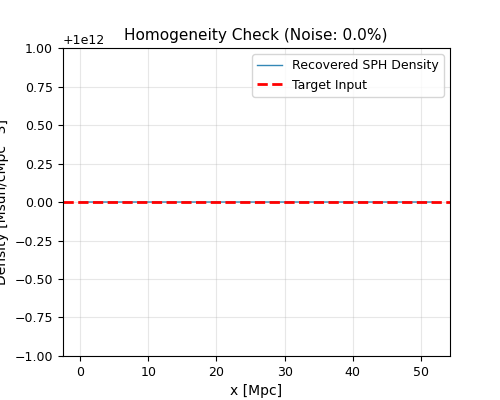

In [27]:
plt.close("all")
plt.figure(figsize=(5, 4))
plt.plot(x_line, density_values, label="Recovered SPH Density", lw=1, alpha=0.8)
plt.axhline(target_dens, color='red', linestyle='--', linewidth=2, label="Target Input")

plt.xlabel("x [Mpc]")
plt.ylabel("Density [Msun/cMpc^3]")
plt.title(f"Homogeneity Check (Noise: {variation:.1f}%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [28]:
v = jnp.full(qv_debug.shape, 1e-8)
qv_debug[:,1:4].shape

(60, 3)

In [29]:
X_H = 0.76
Msun_kg = 1.989e30
Mp_kg = 1.6726e-27
kpc_to_cm = 3.086e21

In [30]:
def get_velocity_sph(quadri_vectors):
    """Velocity [km/s] with Mpc->kpc conversion and NaN protection."""
    qv = np.asarray(quadri_vectors).copy()
    qv[..., 1:4] *= 1e3  # Mpc -> kpc
    
    v = jnp.full(quadri_vectors[:,1:4].shape, 1e2)
    v = np.where(np.isnan(v) | np.isinf(v), 0.0, v)
    
    return v

def velocity_sampler_sph(quadri_vectors):
    return sph.make_field_sampler("Velocities")

def temperature_sampler_sph(quadri_vectors):
    return np.full(np.asarray(quadri_vectors).shape[:-1], 1e4)

def nHI_physical_sampler_sph(quadri_vectors):
    """n_HI [cm⁻³] with Mpc->kpc conversion and zero protection."""
    qv = np.asarray(quadri_vectors).copy()
    qv[..., 1:4] *= 1e3  # Mpc -> kpc
    # So, we pass the qv Mpc and the function does the conversion inside.
    
    rho_comoving = raw_density_sampler(qv) # Msun/kpc³ comoving
    frac_from_sim = jnp.full(len(rho_comoving), 1e-6)
    
    # Convert to physical density
    rho_physical_kpc = rho_comoving * (1 + z_sim)**3 # Msun/kpc³
    conversion_factor_n_H = (Msun_kg / Mp_kg) / (kpc_to_cm**3) # amu/cm³ 
    n_H = rho_physical_kpc * X_H * conversion_factor_n_H # atoms/cm⁻³
    
    fneutral = np.clip(frac_from_sim, 0.0, 1.0)
    n_HI = jnp.full(qv.shape[:-1], 1.7060288688524994e-10)
    print(f"fneutral = {n_HI}")
    
    # Replace zeros with IGM floor value
    n_HI = np.where(n_HI == 0, 1e-12, n_HI)
    n_HI = np.where(np.isnan(n_HI) | np.isinf(n_HI), 1e-12, n_HI)
    
    return n_HI


In [31]:
# Fields: SPH version
fields_sph = Fields({
    "HI": {
        "temperature": ScalarField(temperature_sampler_sph),
        "velocity": VectorField(get_velocity_sph),
        "number_density": ScalarField(nHI_physical_sampler_sph),
        "turbulence": ScalarField(lambda x: jnp.zeros(jnp.asarray(x).shape[:-1])),
        "collisional": ScalarField(lambda x: jnp.zeros(jnp.asarray(x).shape[:-1])),
    }
})

In [32]:
print("Computing optical depth (SPH)...")
tau_sph = od.compute_optical_depth(skewer_bundle,
                                wavelengths, 
                                line_bundle,
                                fields_sph, 
                                compute_mode="vmap")

2026-02-04 10:48:12,789 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, mode=vmap, Voigt impl=ExoJAX
2026-02-04 10:48:12,790 - INFO - [OPTICAL_DEPTH] Extracting 1 skewers with 1024 points each
2026-02-04 10:48:12,790 - INFO - [OPTICAL_DEPTH] Computing line profiles for 1 lines across 1 species using vmap
2026-02-04 10:48:12,949 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (1, 1, 1024, 3961)
2026-02-04 10:48:12,950 - INFO - [OPTICAL_DEPTH] Tiling fields for 1 species to line-level


Computing optical depth (SPH)...


2026-02-04 10:48:13,015 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (1, 1, 1024)
2026-02-04 10:48:13,016 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-02-04 10:48:13,017 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (1, 1, 1024, 3961)
2026-02-04 10:48:13,017 - INFO - [OPTICAL_DEPTH] Reorienting 1 skewers based on photon path direction mask
2026-02-04 10:48:13,020 - INFO - [OPTICAL_DEPTH] Arrays reoriented: quadri_vectors (1, 1024, 4), dtau_dx_m (1, 1, 1024, 3961)
2026-02-04 10:48:13,020 - INFO - [OPTICAL_DEPTH] Performing trapz integration along 1024 spatial points
2026-02-04 10:48:13,021 - INFO - [OPTICAL_DEPTH] Computation complete. Result shape: (1, 1, 3961)


fneutral = [[1.7060289e-10 1.7060289e-10 1.7060289e-10 ... 1.7060289e-10
  1.7060289e-10 1.7060289e-10]]


In [33]:
F_sph = jnp.exp(-tau_sph)
F_over_F0[0,0,:].shape


(3961,)

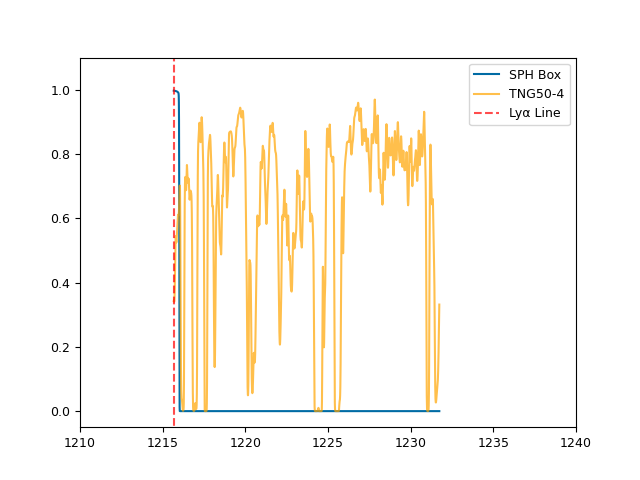

In [34]:
plt.close('all')
plt.plot(wavelengths, F_sph[0,0,:], label='SPH Box')
plt.plot(wavelengths, F_over_F0[0,0,:], label='TNG50-4', color='orange', alpha=0.7)
plt.xlim(1210, 1240)
plt.ylim(-0.05, 1.1)
plt.vlines(1215.67, -2, 2, color='red', linestyles='--', label='Lyα Line', alpha = 0.7 )
plt.legend()
plt.show()

# =================================================================================
### Now we can try to compare with the plot from Fake Spectra: 
# =================================================================================

In [35]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import h5py

# 1. Configuração de Caminhos
# O fake_spectra busca por: base/snapdir_num/snap_num.0.hdf5
BASE_PATH = "/home/STORAGE/TNG50-4"
SNAP_NUM = 25

from fake_spectra.spectra import Spectra

In [36]:
# 2. Skewer Geometry
# On TNG50-4, we need to know the size of the box to find the center.
# read the Header.
snap_file = os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}/snap_{SNAP_NUM:03d}.0.hdf5")
with h5py.File(snap_file, 'r') as f:
    box_size = f['Header'].attrs['BoxSize'] # kpc/h comoving
    redshift = f['Header'].attrs['Redshift']

print(f"Redshift do Snapshot: {redshift:.2f}")
print(f"Tamanho da Caixa: {box_size} kpc/h")
# Vamos colocar o skewer no centro (x, y) e atravessar em z (eixo 3)
center = box_size / 2.0
fs_cofm = np.array([[0.0, center, center]]) # The value on the skewer axis (x=0) is ignored
fs_axis = np.array([1]) # 1=x, 2=y, 3=z

Redshift do Snapshot: 3.01
Tamanho da Caixa: 35000.0 kpc/h


In [37]:
%autoreload

In [38]:
# 'res' é a resolução em km/s. 1.0 km/s é um valor padrão para Lyman-alpha forest.
pixel_res_kms = 1.0

spec = Spectra(
    num=SNAP_NUM,
    base=BASE_PATH,
    cofm=fs_cofm,
    axis=fs_axis,
    res=pixel_res_kms,
    reload_file=True, # Força a extração dos dados do snapshot
    quiet=False,
)
# Extraindo a profundidade óptica (Tau) de Lyman-alpha
# Elemento "H", Ion 1 (HI - Neutro), Linha 1215 (Lya)
tau = spec.get_tau("H", 1, 1215)
flux = np.exp(-tau[0]) # Convertendo Tau para Fluxo Transmitido
# 4. Processamento de Comprimento de Onda
v_max = spec.vmax      # Extensão da caixa em km/s
n_bins = spec.nbins    # Número de pixels
dv = spec.dvbin
vel_axis = np.arange(spec.nbins) * dv # Centro do bin (mais correto fisicamente)
# Comprimento de onda observado: lambda = lambda_repouso * (1 + z) * (1 + v/c)
lambda_lya_rest = 1215.67027 # Angstroms    
c_kms = 2.99792458e5 # Velocidade da luz em km/s
lambda_obs = lambda_lya_rest  * (1 + vel_axis / c_kms)

Reloading from snapshot (will save to:  /home/STORAGE/TNG50-4/snapdir_025/spectra.hdf5  )
1  sightlines. resolution:  1.000137852803097  z= 3.008131071630377
rank = 0 | Interpolation 9.1 percent done
rank = 0 | Interpolation 18.2 percent done
rank = 0 | Interpolation 27.3 percent done
rank = 0 | Interpolation 36.4 percent done
rank = 0 | Interpolation 45.5 percent done
rank = 0 | Interpolation 54.5 percent done
rank = 0 | Interpolation 63.6 percent done
rank = 0 | Interpolation 72.7 percent done
rank = 0 | Interpolation 81.8 percent done
rank = 0 | Interpolation 90.9 percent done


In [39]:
v_box_kms = spec.vmax 
print(f"Applying PBC with box velocity: {v_box_kms:.2f} km/s")

Applying PBC with box velocity: 3961.55 km/s


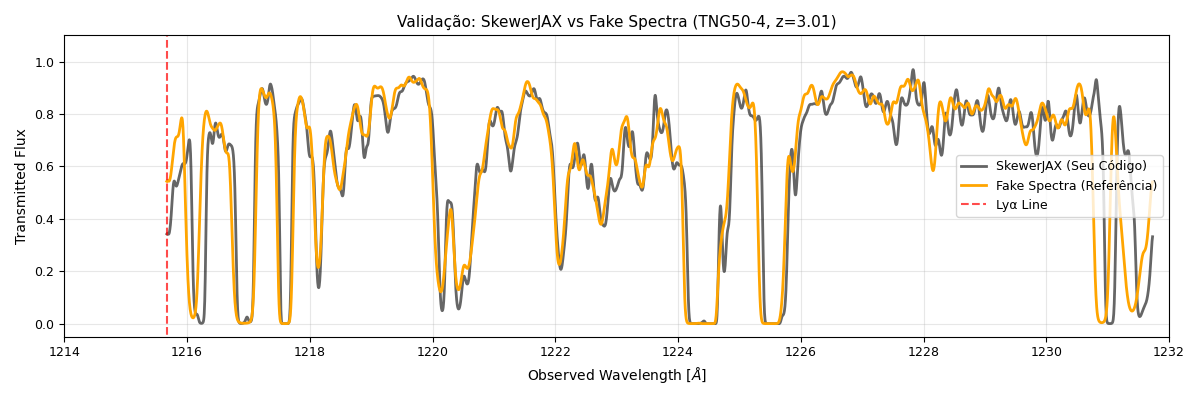

In [40]:
# =============================================================================
# 4. PLOT DE COMPARAÇÃO
# =============================================================================
plt.figure(figsize=(12, 4))

# Plot SkewerJAX (Usando sua variável wavelengths e F_over_F0)
# F_over_F0 tem shape (N_cosmo, N_skewer, N_wave). Assumindo cosmo 0 e skewer 0.
plt.plot(wavelengths,F_over_F0[0,0,:], 
         label='SkewerJAX (Seu Código)', color='black', alpha=0.6, lw=2)

# Plot Fake Spectra
plt.plot(lambda_obs, flux, 
         label='Fake Spectra (Referência)', color='orange', lw=2, alpha=1)

plt.vlines(1215.67, -2, 2, color='red', linestyles='--', label='Lyα Line', alpha = 0.7 )
#plt.vlines(lambda_obs_end, -2, 2, color='red', linestyles='--', label='Lyα Line', alpha = 0.7 )


plt.title(f"Validação: SkewerJAX vs Fake Spectra (TNG50-4, z={z_sim:.2f})")
plt.xlabel(r"Observed Wavelength [$\AA$]")
plt.ylabel("Transmitted Flux")
plt.legend()
plt.xlim(1214, 1232) # Ajuste o zoom conforme necessário para ver as linhas
plt.ylim(-0.05, 1.1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()  

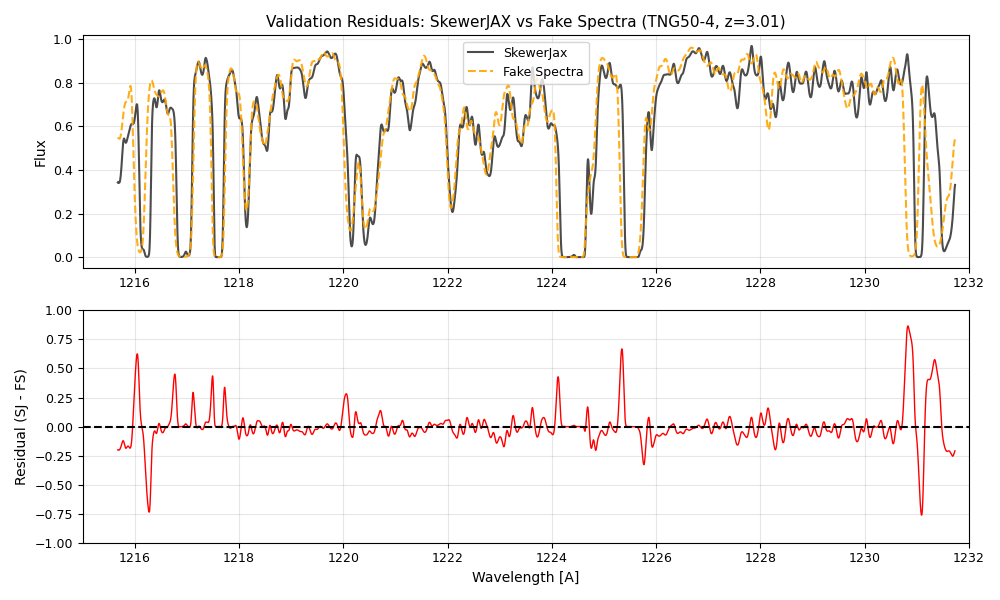

In [41]:
# =============================================================================
# 3. PLOT DE RESÍDUOS (A Prova Real)
# =============================================================================
plt.figure(figsize=(10, 6))

# Plot Principal
plt.subplot(2, 1, 1)
plt.plot(wavelengths, F_over_F0[0,0,:], label='SkewerJax', color='black', alpha=0.7, lw=1.5)
plt.plot(lambda_obs, flux, label='Fake Spectra', color='orange', linestyle='--', alpha=0.9, lw=1.5)
plt.ylabel("Flux")
plt.legend()
plt.title(f"Validation Residuals: SkewerJAX vs Fake Spectra (TNG50-4, z={z_sim:.2f})")
plt.xlim(1215, 1232)
plt.grid(alpha=0.3)

# Plot de Resíduos (Diferença)
plt.subplot(2, 1, 2)
diff = F_over_F0[0,0,:] - flux
plt.plot(lambda_obs, diff, color='red', lw=1)
plt.axhline(0, color='k', linestyle='--')
plt.ylabel("Residual (SJ - FS)")
plt.xlabel("Wavelength [A]")
plt.xlim(1215, 1232)
plt.ylim(-1, 1) # Zoom nos erros pequenos
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()